## Predicting Penguin Species with a scikit-learn Pipeline

In [3]:
import io
import requests
import pandas as pd
from tqdm.auto import tqdm

/Users/shenweizhang/Desktop/ml-pipeline-demo-510-interactive/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
PENGUINS_URL = (
    "https://raw.githubusercontent.com/allisonhorst/"
    "palmerpenguins/main/inst/extdata/penguins.csv"
)

In [9]:
def fetch_penguins(url: str = PENGUINS_URL) -> pd.DataFrame:
  response = requests.get(url, stream=True, timeout=30)
  response.raise_for_status()

  total = int(response.headers.get("Content-Length") or 0)
  chunks = []
  with tqdm(total=total or None, unit="B", unit_scale=True, desc="penguins.csv") as bar:
    for chunk in response.iter_content(chunk_size=1024):
      if chunk:
        chunks.append(chunk)
        bar.update(len(chunk))

  return pd.read_csv(io.BytesIO(b"".join(chunks)))

df = fetch_penguins()

penguins.csv: 15.2kB [00:00, 20.4MB/s]                   


In [10]:
df.head(n=5)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [14]:
NUMERIC = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
TARGET = "species"

def clean_penguins(df: pd.DataFrame) -> pd.DataFrame:
    cleaned = (
        df.dropna()
          .drop(columns=["island", "year"])
          .reset_index(drop=True)
    )
    return pd.get_dummies(cleaned, columns=["sex"], dtype=int)

penguins = clean_penguins(df)

print(penguins.shape)

penguins.columns.tolist()

(333, 7)


['species',
 'bill_length_mm',
 'bill_depth_mm',
 'flipper_length_mm',
 'body_mass_g',
 'sex_female',
 'sex_male']

In [16]:
penguins.head(n=5)

,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex_female,sex_male
0,Adelie,39.1,18.7,181.0,3750.0,0,1
1,Adelie,39.5,17.4,186.0,3800.0,1,0
2,Adelie,40.3,18.0,195.0,3250.0,1,0
3,Adelie,36.7,19.3,193.0,3450.0,1,0
4,Adelie,39.3,20.6,190.0,3650.0,0,1


In [17]:
X = penguins.drop(columns=TARGET)
y = penguins[TARGET]

In [20]:
X.head()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex_female,sex_male
0,39.1,18.7,181.0,3750.0,0,1
1,39.5,17.4,186.0,3800.0,1,0
2,40.3,18.0,195.0,3250.0,1,0
3,36.7,19.3,193.0,3450.0,1,0
4,39.3,20.6,190.0,3650.0,0,1


In [21]:
y.head()

0    Adelie
1    Adelie
2    Adelie
3    Adelie
4    Adelie
Name: species, dtype: str

In [23]:
from sklearn.model_selection import train_test_split

def split_data(X, y, test_size: float = 0.2, random_state: int = 42):
    return train_test_split(
        X,
        y,
        test_size=test_size,
        stratify=y,
        random_state=random_state,
    )

X_train, X_test, y_train, y_test = split_data(X, y)
print(X_train.shape, X_test.shape)

(266, 6) (67, 6)


In [24]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier


def build_model() -> Pipeline:
    return Pipeline([
        ("scaler", StandardScaler()),
        ("clf", AdaBoostClassifier(
            estimator=DecisionTreeClassifier(max_depth=1),
            n_estimators=200,
            random_state=42,
        )),
    ])

In [25]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(build_model(), X_train, y_train, cv=cv, scoring="accuracy")

print(f"CV accuracy: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

CV accuracy: 0.9511 ± 0.0307


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

model = build_model()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred))

Test accuracy: 0.9552
              precision    recall  f1-score   support

      Adelie       1.00      0.93      0.96        29
   Chinstrap       0.88      1.00      0.93        14
      Gentoo       0.96      0.96      0.96        24

    accuracy                           0.96        67
   macro avg       0.94      0.96      0.95        67
weighted avg       0.96      0.96      0.96        67

[[27  1  1]
 [ 0 14  0]
 [ 0  1 23]]


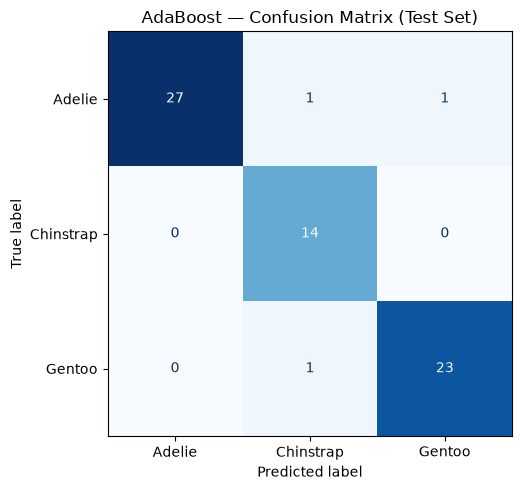

In [27]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=model.classes_,
    display_labels=model.classes_,
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title("AdaBoost — Confusion Matrix (Test Set)")
plt.tight_layout()
# fig.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()